In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os, warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Dense, Dropout, GlobalAveragePooling2D,
                                      BatchNormalization, Input)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import classification_report, confusion_matrix

# Config
IMG_SIZE   = 224
BATCH_SIZE = 32
EPOCHS     = 20
LR         = 0.0001

TRAIN_DIR = "/Users/ahbiswas/Documents/Data_sets/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train"
VALID_DIR = "/Users/ahbiswas/Documents/Data_sets/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid"

In [2]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

valid_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

valid_gen = valid_datagen.flow_from_directory(
    VALID_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

NUM_CLASSES = len(train_gen.class_indices)
print(f"Number of classes: {NUM_CLASSES}")
print(f"Classes: {list(train_gen.class_indices.keys())}")

# Save class names for Streamlit
# import json
# with open("class_names.json", "w") as f:
#     json.dump(train_gen.class_indices, f)

Found 70295 images belonging to 38 classes.
Found 17572 images belonging to 38 classes.
Number of classes: 38
Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'T

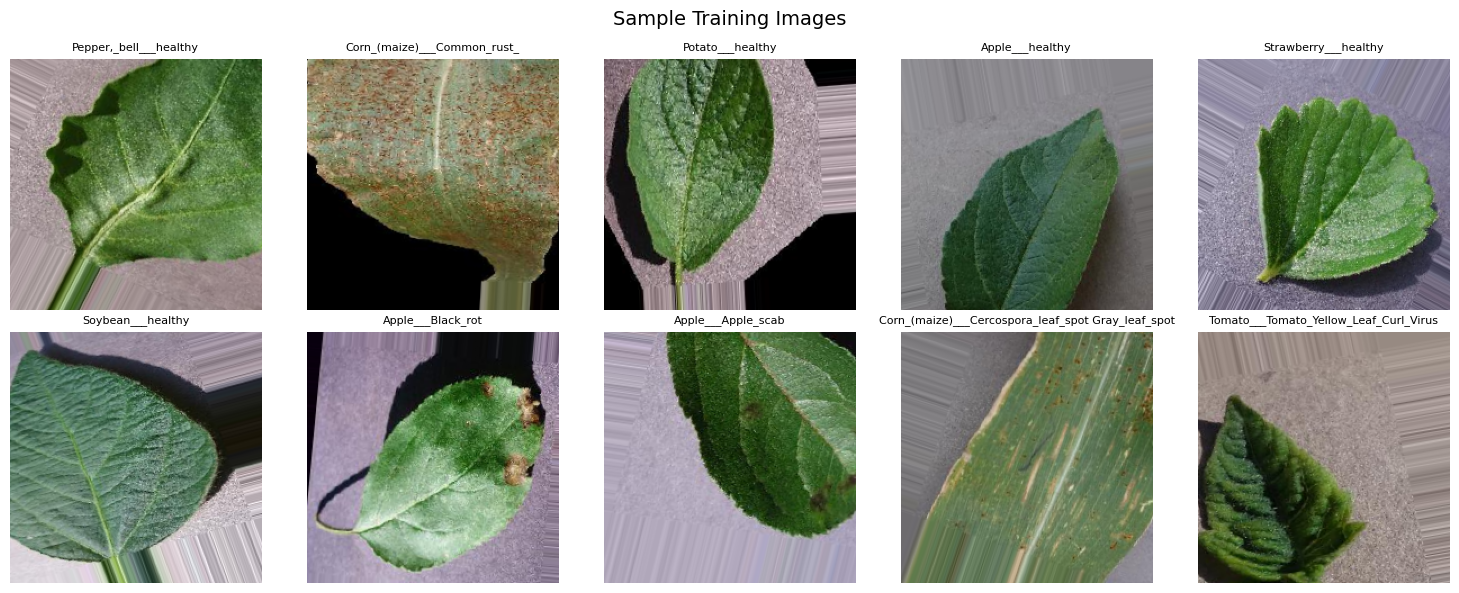

In [3]:
class_names = list(train_gen.class_indices.keys())

images, labels = next(train_gen)
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i])
    ax.set_title(class_names[np.argmax(labels[i])], fontsize=8)
    ax.axis('off')
plt.suptitle("Sample Training Images", fontsize=14)
plt.tight_layout()
plt.show()

In [4]:
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze base model layers
base_model.trainable = False

# Build model
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=Adam(learning_rate=LR),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

2026-04-15 11:34:00.750849: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2
2026-04-15 11:34:00.751062: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-04-15 11:34:00.751072: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2026-04-15 11:34:00.751115: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-15 11:34:00.751130: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,628,838 (10.03 MB)

 Trainable params: 368,294 (1.40 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [5]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, min_lr=1e-6, verbose=1)
]

history = model.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=valid_gen,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20


2026-04-15 11:35:03.355702: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


2197/2197 ━━━━━━━━━━━━━━━━━━━━ 694s 314ms/step - accuracy: 0.5238 - loss: 1.9699 - val_accuracy: 0.8436 - val_loss: 0.5058 - learning_rate: 1.0000e-04
Epoch 2/20
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 830s 378ms/step - accuracy: 0.7351 - loss: 0.9780 - val_accuracy: 0.8827 - val_loss: 0.3744 - learning_rate: 1.0000e-04
Epoch 3/20
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 983s 448ms/step - accuracy: 0.7788 - loss: 0.8060 - val_accuracy: 0.8989 - val_loss: 0.3257 - learning_rate: 1.0000e-04
Epoch 4/20
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 503s 229ms/step - accuracy: 0.8027 - loss: 0.7126 - val_accuracy: 0.9060 - val_loss: 0.2998 - learning_rate: 1.0000e-04
Epoch 5/20
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 1189s 541ms/step - accuracy: 0.8201 - loss: 0.6475 - val_accuracy: 0.9097 - val_loss: 0.2791 - learning_rate: 1.0000e-04
Epoch 6/20
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 396s 180ms/step - accuracy: 0.8310 - loss: 0.5987 - val_accuracy: 0.9135 - val_loss: 0.2667 - learning_rate: 1.0000e-04
Epoch 7/20
2197/2197 ━━━━━━━━━━━━━━━━━

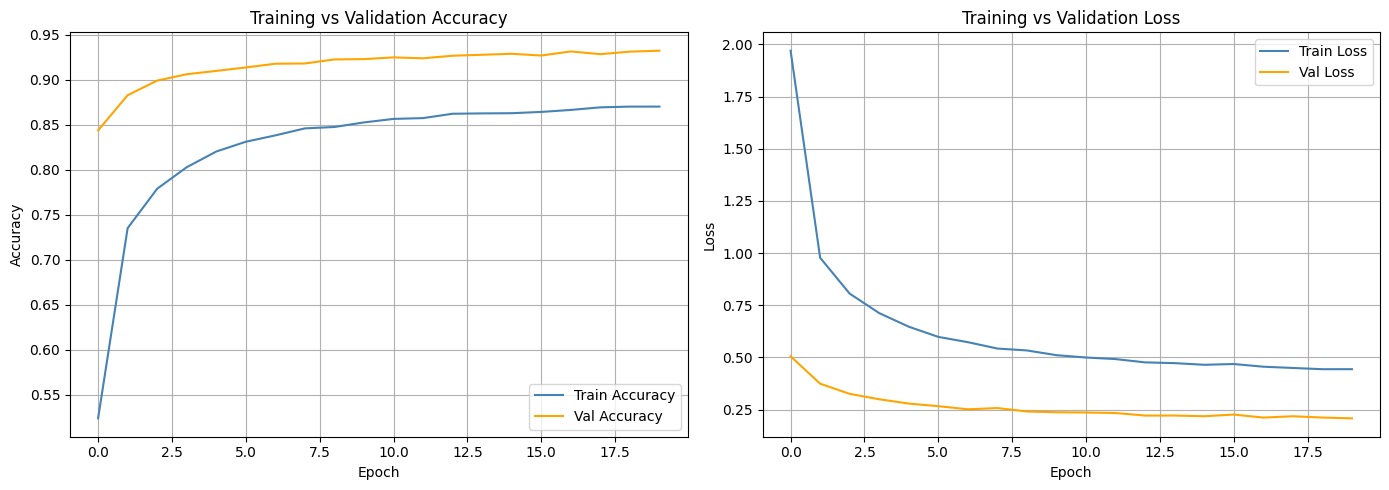

In [8]:
def plot_history(h1, h2=None):
    acc     = h1.history['accuracy']
    val_acc = h1.history['val_accuracy']
    loss    = h1.history['loss']
    val_loss= h1.history['val_loss']

    if h2:
        acc     += h2.history['accuracy']
        val_acc += h2.history['val_accuracy']
        loss    += h2.history['loss']
        val_loss+= h2.history['val_loss']

    epochs_range = range(len(acc))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs_range, acc,     label='Train Accuracy',  color='steelblue')
    axes[0].plot(epochs_range, val_acc, label='Val Accuracy',    color='orange')
    axes[0].set_title('Training vs Validation Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(epochs_range, loss,     label='Train Loss',  color='steelblue')
    axes[1].plot(epochs_range, val_loss, label='Val Loss',    color='orange')
    axes[1].set_title('Training vs Validation Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.savefig("training_plot.png", dpi=150)
    plt.show()

plot_history(history)

550/550 ━━━━━━━━━━━━━━━━━━━━ 65s 115ms/step

===== Classification Report =====

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.96      0.92      0.94       504
                                 Apple___Black_rot       0.96      0.99      0.97       497
                          Apple___Cedar_apple_rust       0.99      0.96      0.98       440
                                   Apple___healthy       0.97      0.97      0.97       502
                               Blueberry___healthy       1.00      0.96      0.98       454
          Cherry_(including_sour)___Powdery_mildew       0.99      0.97      0.98       421
                 Cherry_(including_sour)___healthy       0.97      1.00      0.98       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.93      0.88      0.91       410
                       Corn_(maize)___Common_rust_       0.96      1.00      0.98       477

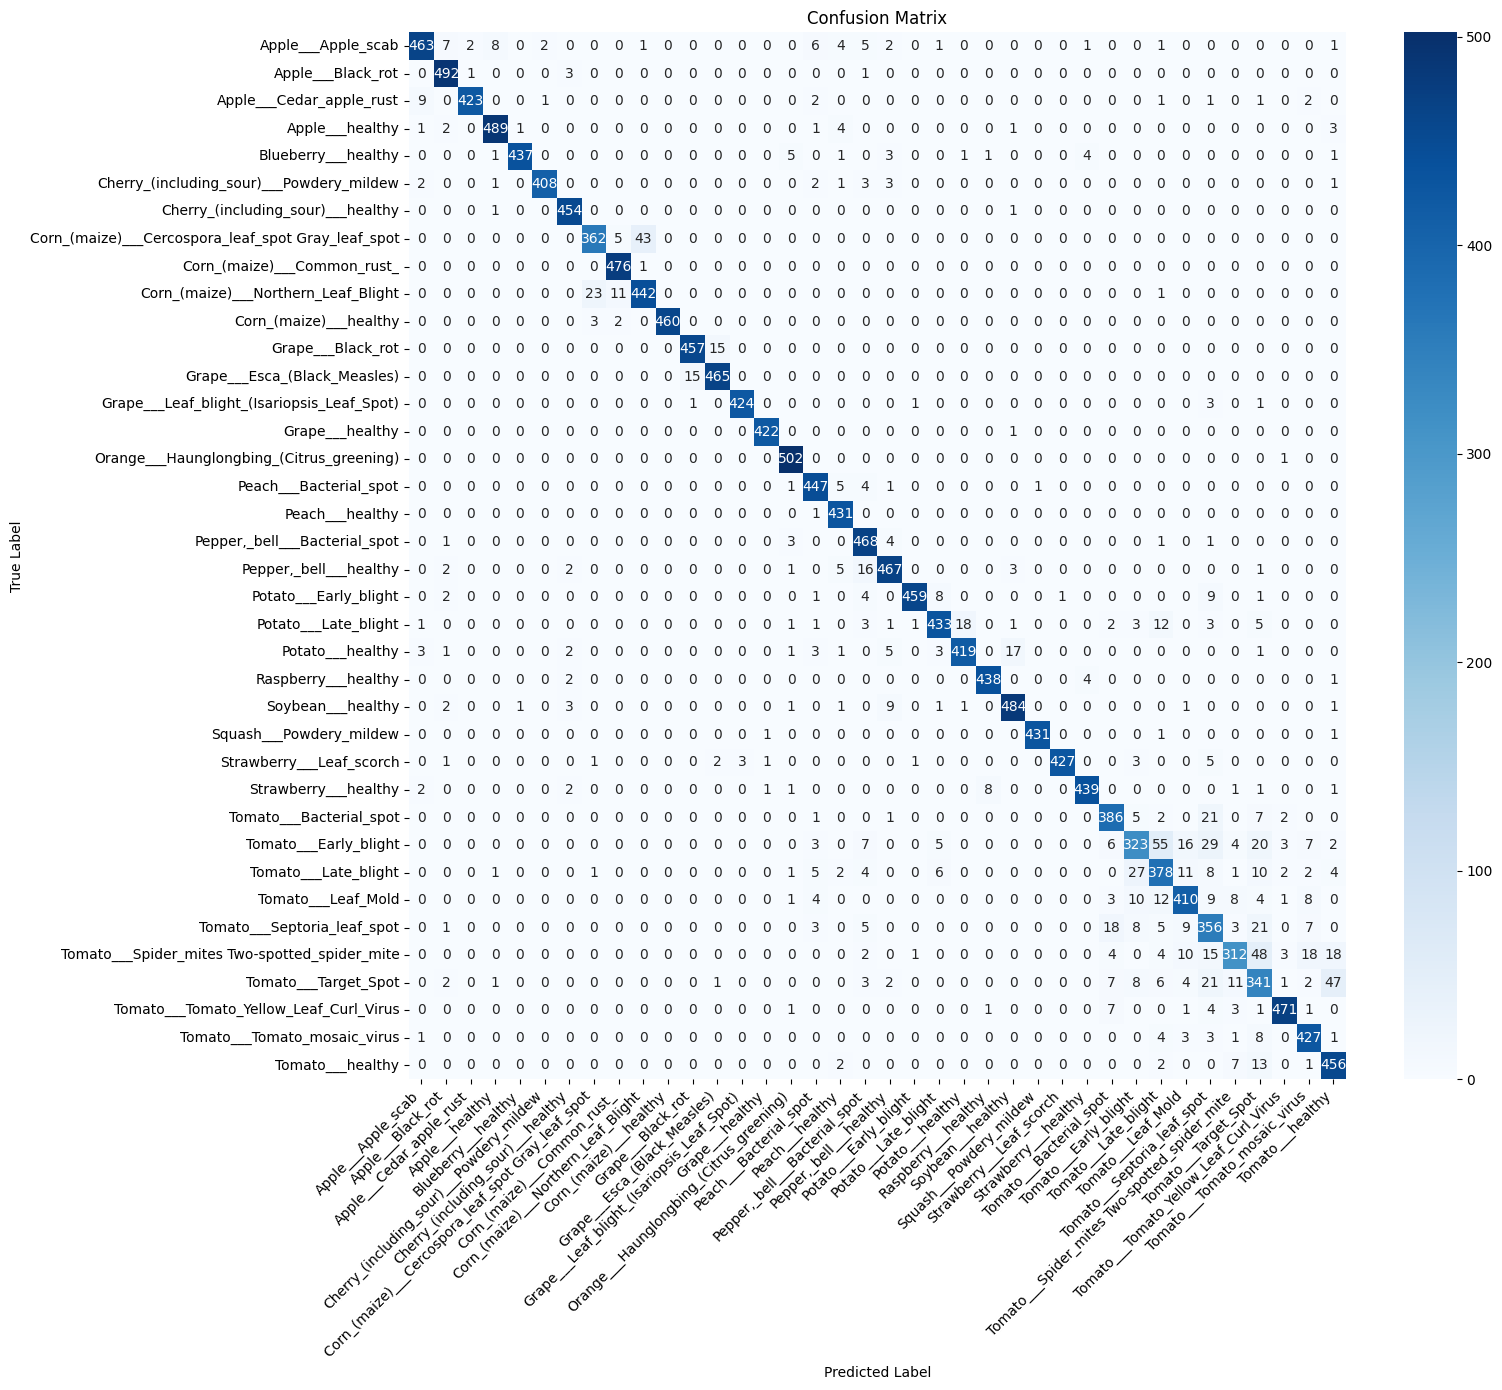

In [9]:
from sklearn.metrics import classification_report, confusion_matrix

valid_gen.reset()
y_pred_probs = model.predict(valid_gen, verbose=1)
y_pred  = np.argmax(y_pred_probs, axis=1)
y_true  = valid_gen.classes

# Classification Report
print("\n===== Classification Report =====\n")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(16, 14))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()